# Pilot: confidence cascade of two CNN agents on Cassava leaf disease classification

Pilot run for the Results section of the article *Multi-Agent AI System for Plant Disease Classification*. It uses a 10% subset of the Cassava training and validation splits and the full test split, two base agents (MobileNetV2, ResNet50), and three random seeds (0, 1, 2). Configurations compared: each agent alone, soft voting, and a confidence cascade (MobileNetV2 first, escalation to soft voting when the confidence is below a threshold tau).

Runtime: Google Colab, T4 GPU.

## 1. Setup
Installs a package that is missing in the Colab runtime and removes a partly downloaded copy of the dataset.

## 2. Data
Loads the `cassava` dataset from TensorFlow Datasets with `train[:10%]`, `validation[:10%]` and the full `test` split. Prints the size of each split and the number of images per class (cbb, cbsd, cgm, cmd, healthy).

In [ ]:
!pip install -q importlib_resources
!rm -rf /root/tensorflow_datasets/cassava

## 3. Base agents
Defines the preprocessing (resize to 224x224, model-specific input scaling) and the agent model: an ImageNet-pre-trained backbone (frozen) with a new dropout and softmax classification head. This cell also runs a first training of MobileNetV2 and ResNet50 (5 epochs, Adam) and prints test accuracy and macro-F1 for each.

In [ ]:
import tensorflow_datasets as tfds
import numpy as np

(train, val, test), info = tfds.load(
    "cassava",
    split=["train[:10%]", "validation[:10%]", "test"],
    as_supervised=True,
    with_info=True,
)
names = info.features["label"].names
print(names)
for n, d in [("train", train), ("val", val), ("test", test)]:
    y = np.array([int(l) for _, l in d])
    print(n, len(y), np.bincount(y, minlength=len(names)))

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.FOCL7B_0.1.0/cassava-train.tfrecord-[0-9][0-9][0-9][0-9…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.FOCL7B_0.1.0/cassava-test.tfrecord-[0-9][0-9][0-9][0-9]…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.FOCL7B_0.1.0/cassava-validation.tfrecord-[0-9][0-9][0-9…

Dataset cassava downloaded and prepared to /root/tensorflow_datasets/cassava/0.1.0. Subsequent calls will reuse this data.
['cbb', 'cbsd', 'cgm', 'cmd', 'healthy']
train 566 [ 32 157  76 265  36]
val 189 [14 49 31 90  5]
test 1885 [155 481 258 886 105]


In [ ]:
import tensorflow as tf, numpy as np
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2, ResNet50
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as prep_m
from tensorflow.keras.applications.resnet50 import preprocess_input as prep_r
from sklearn.metrics import f1_score

tf.keras.utils.set_random_seed(0)
K = len(names)

def make_ds(d, prep, shuffle=False):
    def f(x, y):
        x = tf.image.resize(x, (224, 224))
        return prep(tf.cast(x, tf.float32)), y
    d = d.map(f, num_parallel_calls=tf.data.AUTOTUNE)
    if shuffle:
        d = d.shuffle(1000, seed=0)
    return d.batch(32).prefetch(tf.data.AUTOTUNE)

def build(base_cls):
    base = base_cls(include_top=False, weights="imagenet",
                    input_shape=(224, 224, 3), pooling="avg")
    base.trainable = False
    out = layers.Dense(K, activation="softmax")(layers.Dropout(0.2)(base.output))
    m = models.Model(base.input, out)
    m.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

probs = {}
for name, cls, prep in [("MobileNetV2", MobileNetV2, prep_m),
                        ("ResNet50", ResNet50, prep_r)]:
    m = build(cls)
    m.fit(make_ds(train, prep, True), validation_data=make_ds(val, prep),
          epochs=5, verbose=2)
    test_ds = make_ds(test, prep)
    probs[name] = m.predict(test_ds, verbose=0)
    y_test = np.concatenate([yy.numpy() for _, yy in test_ds])
    f1 = f1_score(y_test, probs[name].argmax(1), average="macro")
    acc = (probs[name].argmax(1) == y_test).mean()
    print(f"{name}: accuracy={acc:.4f}, macro-F1={f1:.4f}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
18/18 - 27s - 2s/step - accuracy: 0.4452 - loss: 1.4788 - val_accuracy: 0.5556 - val_loss: 1.1627
Epoch 2/5
18/18 - 3s - 147ms/step - accuracy: 0.5742 - loss: 1.0998 - val_accuracy: 0.6085 - val_loss: 1.0218
Epoch 3/5
18/18 - 2s - 138ms/step - accuracy: 0.6307 - loss: 0.9408 - val_accuracy: 0.6508 - val_loss: 0.9455
Epoch 4/5
18/18 - 3s - 139ms/step - accuracy: 0.6714 - loss: 0.8403 - val_accuracy: 0.6667 - val_loss: 0.8962
Epoch 5/5
18/18 - 3s - 146ms/step - accuracy: 0.7208 - loss: 0.7726 - val_accuracy: 0.6667 - val_loss: 0.8990
MobileNetV2: accuracy=0.6727, macro-F1=0.4718
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
18/18 - 30s - 2s/step - accuracy: 0.4700 - loss: 1.4754 - val_accuracy: 0.6349 - val_loss: 1.0300
Epoch 2/5
18/18 - 4s - 248ms/step - accuracy: 0.6060 - loss: 1.0284 - val_accuracy: 0.6614 - val_loss: 0.9649
Epoch 3/5
18/18 - 4s - 246ms/step - accuracy: 0.6625 - loss: 0.8898 - val_accuracy: 0.65

## 4. Three seeds: single agents, soft voting, cascade
For each seed (0, 1, 2) both agents are retrained and their class probabilities on the validation and test splits are saved. Configurations evaluated on the test split by macro-F1:

- each agent alone,
- soft voting (mean of the two probability vectors),
- cascade: MobileNetV2 predicts when its maximum probability is at least tau, otherwise the soft-voting prediction is used.

The threshold tau is chosen per seed on the validation split only: the smallest value on the grid 0.30 to 1.00 (step 0.05) for which the cascade macro-F1 is at most 0.01 below that of soft voting. The table reports tau, the escalation rate rho (share of test images sent to the second stage), and the macro-F1 per seed, followed by mean and sample standard deviation.

In [ ]:
def make_ds(d, prep, shuffle=False, seed=0):
    def f(x, y):
        x = tf.image.resize(x, (224, 224))
        return prep(tf.cast(x, tf.float32)), y
    d = d.map(f, num_parallel_calls=tf.data.AUTOTUNE)
    if shuffle:
        d = d.shuffle(1000, seed=seed)
    return d.batch(32).prefetch(tf.data.AUTOTUNE)

yv = np.concatenate([y.numpy() for _, y in make_ds(val, prep_m)])
yt = np.concatenate([y.numpy() for _, y in make_ds(test, prep_m)])
mf1 = lambda y, p: f1_score(y, p, average="macro")

def casc(pM, pE, tau):
    esc = pM.max(1) < tau
    return np.where(esc, pE.argmax(1), pM.argmax(1)), esc.mean()

taus = np.round(np.arange(0.3, 1.0001, 0.05), 2)
allp, rows = {}, []

for seed in [0, 1, 2]:
    P = {}
    for key, cls, prep in [("M", MobileNetV2, prep_m), ("R", ResNet50, prep_r)]:
        tf.keras.utils.set_random_seed(seed)
        m = build(cls)
        m.fit(make_ds(train, prep, True, seed),
              validation_data=make_ds(val, prep), epochs=5, verbose=0)
        P[key] = (m.predict(make_ds(val, prep), verbose=0),
                  m.predict(make_ds(test, prep), verbose=0))
    allp[seed] = P
    (Mv, Mt), (Rv, Rt) = P["M"], P["R"]
    Ev, Et = (Mv + Rv) / 2, (Mt + Rt) / 2          # soft voting
    target = mf1(yv, Ev.argmax(1)) - 0.01           # tau chosen on VAL only
    tau = [t for t in taus if mf1(yv, casc(Mv, Ev, t)[0]) >= target][0]
    pred, rho = casc(Mt, Et, tau)
    rows.append(dict(seed=seed, tau=tau, rho=rho,
                     MobileNetV2=mf1(yt, Mt.argmax(1)),
                     ResNet50=mf1(yt, Rt.argmax(1)),
                     SoftVoting=mf1(yt, Et.argmax(1)),
                     Cascade=mf1(yt, pred)))
    print("seed", seed, "done")

import pandas as pd
df = pd.DataFrame(rows)
print(df.round(4))
print(df.drop(columns="seed").agg(["mean", "std"]).round(4))

seed 0 done
seed 1 done
seed 2 done
   seed   tau     rho  MobileNetV2  ResNet50  SoftVoting  Cascade
0     0  0.60  0.3613       0.4718    0.5367      0.5255   0.5137
1     1  0.65  0.5215       0.5315    0.5666      0.5752   0.5718
2     2  0.35  0.0334       0.5063    0.5679      0.5594   0.5162
         tau     rho  MobileNetV2  ResNet50  SoftVoting  Cascade
mean  0.5333  0.3054       0.5032    0.5570      0.5533   0.5339
std   0.1607  0.2488       0.0300    0.0177      0.0254   0.0329


## 5. Additional analyses
1. Sensitivity of the cascade to tau: test macro-F1 against escalation rate rho (mean over seeds); the figure is saved as `tau_sensitivity.pdf`. This curve is descriptive and is not used to choose tau.
2. Error analysis for seed 0: per-class F1 of ResNet50, soft voting and the cascade, and the confusion matrix of the cascade (`confusion_cascade.pdf`).
3. CPU latency per image at batch size 1 (median of 60 forward passes after 5 warm-up passes, random weights, forward pass only). The expected cascade latency is computed as t_M + rho * t_R using the measured values.

     tau    rho  macroF1
0   0.30  0.009   0.5045
1   0.35  0.039   0.5110
2   0.40  0.094   0.5237
3   0.45  0.169   0.5284
4   0.50  0.253   0.5357
5   0.55  0.332   0.5448
6   0.60  0.405   0.5485
7   0.65  0.477   0.5506
8   0.70  0.552   0.5509
9   0.75  0.628   0.5524
10  0.80  0.699   0.5530
11  0.85  0.773   0.5533
12  0.90  0.862   0.5533
13  0.95  0.946   0.5533
14  1.00  1.000   0.5533
Per-class F1 (seed 0):
ResNet50 {'cbb': np.float64(0.102), 'cbsd': np.float64(0.681), 'cgm': np.float64(0.441), 'cmd': np.float64(0.836), 'healthy': np.float64(0.623)}
SoftVoting {'cbb': np.float64(0.049), 'cbsd': np.float64(0.685), 'cgm': np.float64(0.424), 'cmd': np.float64(0.839), 'healthy': np.float64(0.63)}
Cascade {'cbb': np.float64(0.025), 'cbsd': np.float64(0.674), 'cgm': np.float64(0.421), 'cmd': np.float64(0.833), 'healthy': np.float64(0.615)}
test size: 1885 per class: [155 481 258 886 105]
tM=240.0 ms, tR=442.0 ms, rho=0.305, expected cascade=375.0 ms, soft voting=682.0 ms


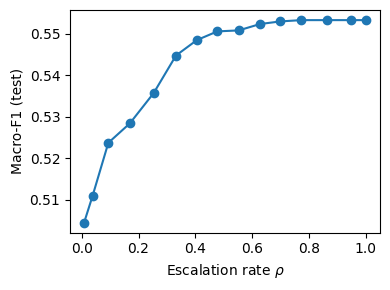

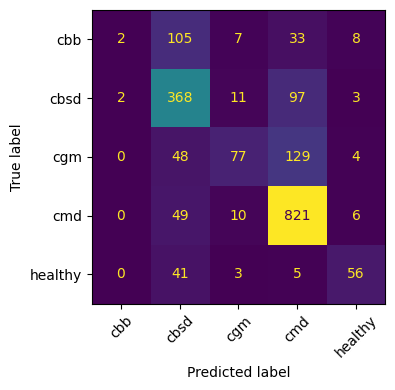

In [ ]:
import matplotlib.pyplot as plt, time
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1) sensitivity of the cascade to tau (test set, mean over seeds)
res = {t: [] for t in taus}
for s, P in allp.items():
    (Mv, Mt), (Rv, Rt) = P["M"], P["R"]
    Et = (Mt + Rt) / 2
    for t in taus:
        pr, rho = casc(Mt, Et, t)
        res[t].append((mf1(yt, pr), rho))
f1m = [np.mean([a for a, _ in res[t]]) for t in taus]
rhm = [np.mean([b for _, b in res[t]]) for t in taus]
fig, ax = plt.subplots(figsize=(4, 3))
ax.plot(rhm, f1m, "o-")
ax.set_xlabel("Escalation rate $\\rho$")
ax.set_ylabel("Macro-F1 (test)")
fig.tight_layout(); fig.savefig("tau_sensitivity.pdf")
print(pd.DataFrame({"tau": taus, "rho": np.round(rhm, 3), "macroF1": np.round(f1m, 4)}))

# 2) error analysis: seed 0, soft voting and cascade
(Mv, Mt), (Rv, Rt) = allp[0]["M"], allp[0]["R"]
Et = (Mt + Rt) / 2
pc, _ = casc(Mt, Et, rows[0]["tau"])
print("Per-class F1 (seed 0):")
for nm, pr in [("ResNet50", Rt.argmax(1)), ("SoftVoting", Et.argmax(1)), ("Cascade", pc)]:
    print(nm, dict(zip(names, np.round(f1_score(yt, pr, average=None), 3))))
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(yt, pc), display_labels=names).plot(ax=ax, xticks_rotation=45, colorbar=False)
fig.tight_layout(); fig.savefig("confusion_cascade.pdf")
print("test size:", len(yt), "per class:", np.bincount(yt))

# 3) CPU latency, batch size 1 (weights do not matter for timing)
def lat(base_cls, prep, n=60):
    m = base_cls(include_top=False, weights=None, input_shape=(224, 224, 3), pooling="avg")
    x = np.random.rand(1, 224, 224, 3).astype("float32")
    with tf.device("/CPU:0"):
        for _ in range(5): m(x, training=False)
        t = []
        for _ in range(n):
            a = time.perf_counter(); m(x, training=False); t.append(time.perf_counter() - a)
    return np.median(t) * 1000
tM, tR = lat(MobileNetV2, prep_m), lat(ResNet50, prep_r)
rho = df["rho"].mean()
print(f"tM={tM:.1f} ms, tR={tR:.1f} ms, rho={rho:.3f}, expected cascade={tM + rho * tR:.1f} ms, soft voting={tM + tR:.1f} ms")

In [ ]:
for n, d in [("train", train), ("val", val), ("test", test)]:
    y = np.array([int(l) for _, l in d])
    print(n, len(y), dict(zip(names, np.bincount(y, minlength=len(names)))))

train 566 {'cbb': np.int64(32), 'cbsd': np.int64(157), 'cgm': np.int64(76), 'cmd': np.int64(265), 'healthy': np.int64(36)}
val 189 {'cbb': np.int64(14), 'cbsd': np.int64(49), 'cgm': np.int64(31), 'cmd': np.int64(90), 'healthy': np.int64(5)}
test 1885 {'cbb': np.int64(155), 'cbsd': np.int64(481), 'cgm': np.int64(258), 'cmd': np.int64(886), 'healthy': np.int64(105)}


## 6. Software and hardware
Python, TensorFlow, TensorFlow Datasets, scikit-learn, NumPy and pandas versions, the GPU model and the CPU model of the Colab runtime.